<a href="https://colab.research.google.com/github/safnanazar04-cmyk/DSA_Exit_Exam/blob/main/Exit_Exam_Safna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Data understanding and Exploration

In [3]:
df = pd.read_csv("/content/drive/MyDrive/DSA_Exit_Exam/G3.csv")


In [83]:
df.head()


,enterprise_group_id,display_name,enterprise_group_name,group_root_lei,enterprise_group_jurisdiction,enterprise_group_entity_status,website,company_type,employees,employees_year,...,market_cap_date,legal_units_count,direct_subsidiaries_count,max_hierarchy_depth,is_standalone_entity,website_source,employees_source,revenue_source,net_income_source,market_cap_source
0,EG_03260722,Morgan Stanley,MORGAN STANLEY,IGJSJL3JD5P30I6NJZ34,US-DE,ACTIVE,morganstanley.com,PUBLIC,83000.0,2025.0,...,2025-12-31,1013,173.0,8.0,False,morganstanley.com,sec.gov,sec.gov,sec.gov,finance.yahoo.com
1,EG_03256960,Bank of America,BANK OF AMERICA CORPORATION,9DJT3UXIJIZJI4WXO774,US-DE,ACTIVE,bankofamerica.com,PUBLIC,213000.0,2025.0,...,2025-12-31,761,155.0,5.0,False,bankofamerica.com,sec.gov,sec.gov,https://investor.bankofamerica.com/regulatory-...,macrotrends.net
2,EG_01804232,Citigroup,CITIGROUP INC.,6SHGI4ZSSLCXXQSBB395,US-DE,ACTIVE,citigroup.com,PUBLIC,226000.0,2025.0,...,2025-12-31,742,22.0,9.0,False,citigroup.com,sec.gov,tradingview.com,tradingview.com,uk.finance.yahoo.com
3,EG_02027196,Goldman Sachs,"THE GOLDMAN SACHS GROUP, INC.",784F5XWPLTWKTBV3E584,US-DE,ACTIVE,https://www.goldmansachs.com,PUBLIC,47400.0,2025.0,...,2025-12-31,568,190.0,7.0,False,goldmansachs.com,sec.gov,goldmansachs.com,goldmansachs.com,finance.yahoo.com
4,EG_03266820,Siemens,Siemens Aktiengesellschaft,W38RGI023J3WT1HWRP32,DE,ACTIVE,siemens.com,PUBLIC,318000.0,2025.0,...,2025-09-30,568,454.0,3.0,False,siemens.com,siemens.com,siemens.com,siemens.com,siemens.com


In [84]:
df.shape


(1599, 28)

In [85]:
df.columns


Index(['enterprise_group_id', 'display_name', 'enterprise_group_name',
       'group_root_lei', 'enterprise_group_jurisdiction',
       'enterprise_group_entity_status', 'website', 'company_type',
       'employees', 'employees_year', 'revenue', 'revenue_currency',
       'revenue_year', 'net_income', 'net_income_currency', 'net_income_year',
       'market_cap', 'market_cap_currency', 'market_cap_date',
       'legal_units_count', 'direct_subsidiaries_count', 'max_hierarchy_depth',
       'is_standalone_entity', 'website_source', 'employees_source',
       'revenue_source', 'net_income_source', 'market_cap_source'],
      dtype='object')

In [86]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 28 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   enterprise_group_id             1599 non-null   object 
 1   display_name                    1599 non-null   object 
 2   enterprise_group_name           1599 non-null   object 
 3   group_root_lei                  1599 non-null   object 
 4   enterprise_group_jurisdiction   1599 non-null   object 
 5   enterprise_group_entity_status  1599 non-null   object 
 6   website                         1578 non-null   object 
 7   company_type                    1597 non-null   object 
 8   employees                       1557 non-null   float64
 9   employees_year                  1556 non-null   float64
 10  revenue                         1587 non-null   float64
 11  revenue_currency                1587 non-null   object 
 12  revenue_year                    15

In [89]:
df.isna().sum()


,0
enterprise_group_id,0
display_name,0
enterprise_group_name,0
group_root_lei,0
enterprise_group_jurisdiction,0
enterprise_group_entity_status,0
website,21
company_type,2
employees,42
employees_year,43


In [90]:
df.duplicated().sum()


np.int64(0)

In [91]:
df = df.drop_duplicates().copy()


In [92]:
df = df.dropna(subset=['revenue']).reset_index(drop=True)


In [87]:
df.describe()


,employees,employees_year,revenue,revenue_year,net_income,net_income_year,market_cap,legal_units_count,direct_subsidiaries_count,max_hierarchy_depth
count,1.557000e+03,1556.000000,1.587000e+03,1586.000000,1.599000e+03,1599.000000,1.214000e+03,1599.000000,1591.000000,1591.000000
mean,4.150329e+04,2024.953728,9.406044e+11,2024.928752,7.895350e+10,2024.914321,2.070724e+12,34.240775,17.174733,2.051540
std,9.872947e+04,0.298623,1.102876e+13,0.440067,1.216758e+12,0.459405,4.945418e+13,61.311217,28.363270,1.052034
min,0.000000e+00,2023.000000,-3.518000e+09,2012.000000,-1.060000e+12,2012.000000,8.270000e+06,1.000000,0.000000,0.000000
25%,2.900000e+03,2025.000000,2.292000e+09,2025.000000,5.681000e+07,2025.000000,3.682500e+09,11.000000,5.000000,1.000000
50%,1.300000e+04,2025.000000,9.627000e+09,2025.000000,5.889000e+08,2025.000000,1.944250e+10,17.000000,9.000000,2.000000
75%,4.100000e+04,2025.000000,3.604668e+10,2025.000000,3.414500e+09,2025.000000,8.862500e+10,34.000000,17.000000,2.000000
max,2.100000e+06,2026.000000,3.336000e+14,2026.000000,4.520000e+13,2026.000000,1.716780e+15,1013.000000,454.000000,9.000000


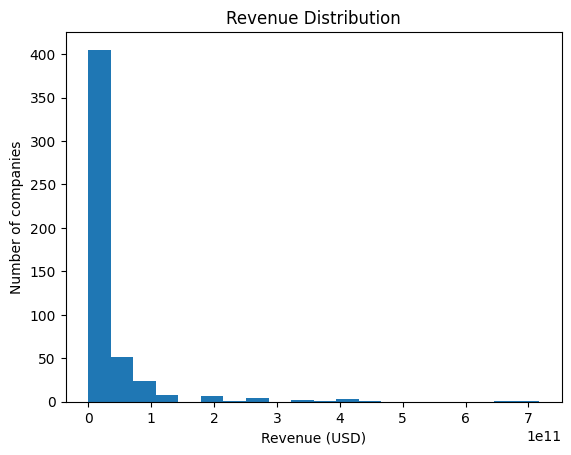

In [153]:
plt.hist(revenue, bins=20)
plt.xlabel("Revenue (USD)")
plt.ylabel("Number of companies")
plt.title("Revenue Distribution")
plt.show()

Data preprocessing

In [156]:
df = df.dropna(subset=["revenue"])

numeric_cols = df.select_dtypes(include="number").columns.drop("revenue", errors="ignore")
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

text_cols = df.select_dtypes(include="object").columns
for col in text_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

In [157]:
df.isna().sum()

,0
enterprise_group_id,0
display_name,0
enterprise_group_name,0
group_root_lei,0
enterprise_group_jurisdiction,0
enterprise_group_entity_status,0
website,0
company_type,0
employees,0
employees_year,0


In [158]:
df = pd.get_dummies(df, columns=["company_type"], drop_first=True, dtype=int)

print(df.head())

  enterprise_group_id     display_name          enterprise_group_name  \
0         EG_03260722   Morgan Stanley                 MORGAN STANLEY   
1         EG_03256960  Bank of America    BANK OF AMERICA CORPORATION   
2         EG_01804232        Citigroup                 CITIGROUP INC.   
3         EG_02027196    Goldman Sachs  THE GOLDMAN SACHS GROUP, INC.   
4         EG_03266820          Siemens     Siemens Aktiengesellschaft   

         group_root_lei enterprise_group_jurisdiction  \
0  IGJSJL3JD5P30I6NJZ34                         US-DE   
1  9DJT3UXIJIZJI4WXO774                         US-DE   
2  6SHGI4ZSSLCXXQSBB395                         US-DE   
3  784F5XWPLTWKTBV3E584                         US-DE   
4  W38RGI023J3WT1HWRP32                            DE   

  enterprise_group_entity_status                       website  employees  \
0                         ACTIVE             morganstanley.com    83000.0   
1                         ACTIVE             bankofamerica.com  

In [159]:
df = df[df["revenue_currency"] == "USD"]

numeric = df.select_dtypes(include="number")
correlations = numeric.corr()["revenue"].drop(
    ["revenue", "revenue_year"], errors="ignore"
).abs().sort_values(ascending=False)

print("Most relevant numeric features:")
print(correlations.head(5))

Most relevant numeric features:
employees                    0.703097
net_income                   0.653574
market_cap                   0.561558
direct_subsidiaries_count    0.185466
legal_units_count            0.167909
Name: revenue, dtype: float64


EDA

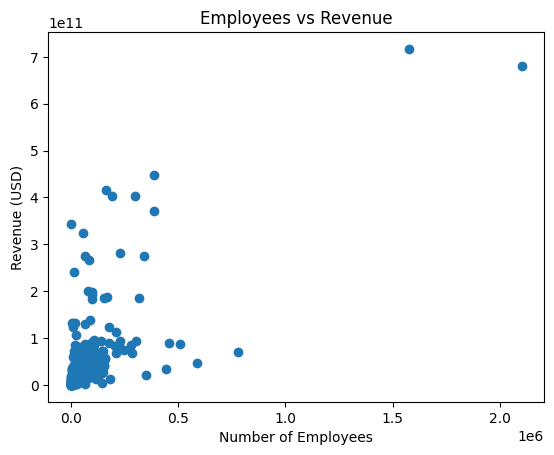

In [161]:
plt.scatter(df["employees"], df["revenue"])
plt.xlabel("Number of Employees")
plt.ylabel("Revenue (USD)")
plt.title("Employees vs Revenue")
plt.show()

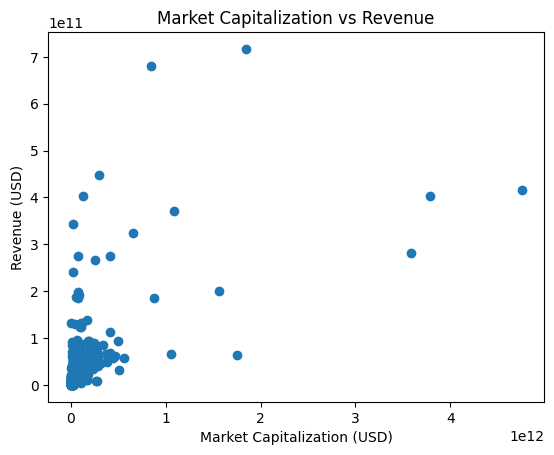

In [163]:
plt.scatter(df["market_cap"], df["revenue"])
plt.xlabel("Market Capitalization (USD)")
plt.ylabel("Revenue (USD)")
plt.title("Market Capitalization vs Revenue")
plt.show()

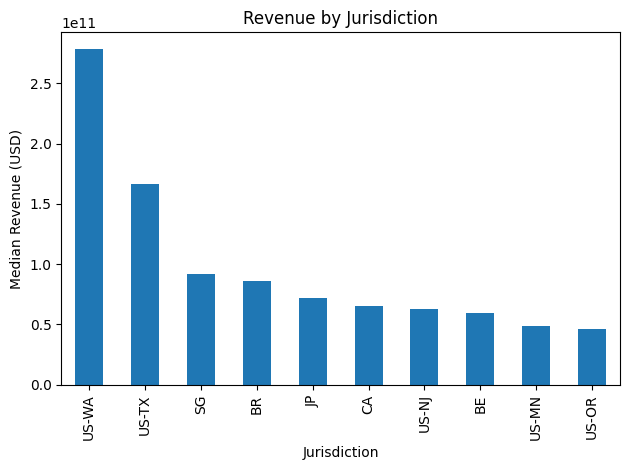

In [167]:
df = df[(df["revenue_currency"] == "USD") & (df["revenue"] > 0)]
top = df.groupby("enterprise_group_jurisdiction")["revenue"].median().nlargest(10)
top.plot(kind="bar")
plt.xlabel("Jurisdiction")
plt.ylabel("Median Revenue (USD)")
plt.title("Revenue by Jurisdiction")
plt.tight_layout()
plt.show()

In [98]:
numeric_cols = df.drop(columns=['revenue']).select_dtypes(include='number').columns.tolist()


In [180]:
numeric_cols


Index(['employees', 'employees_year', 'revenue_year', 'net_income',
       'net_income_year', 'market_cap', 'legal_units_count',
       'direct_subsidiaries_count', 'max_hierarchy_depth'],
      dtype='object')

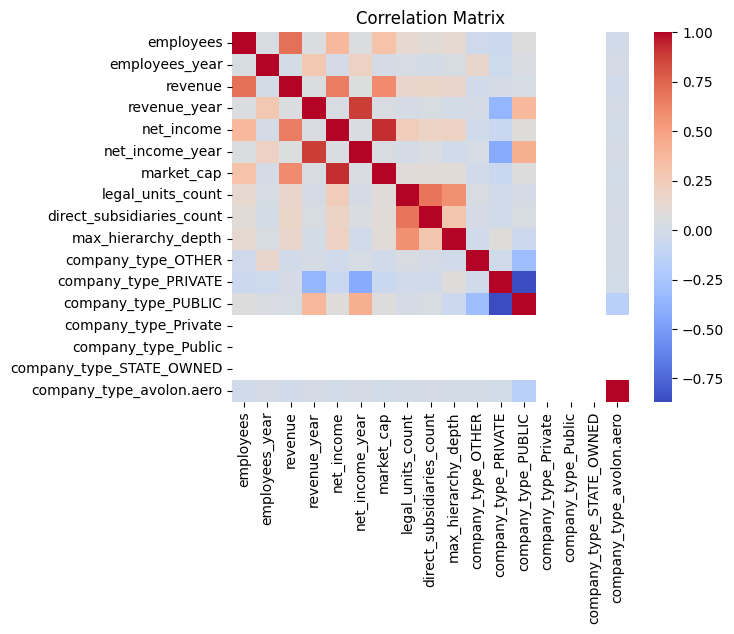

In [240]:
correlation = df.select_dtypes(include='number').corr()
if len(correlation.columns) > 1:
    sns.heatmap(correlation, annot=len(correlation.columns) <= 10, cmap='coolwarm')
    plt.title('Correlation Matrix')
    plt.show()


In [183]:
X = df.drop(columns=['revenue'])


In [184]:
y = df['revenue']


In [185]:
X.head()


,enterprise_group_id,display_name,enterprise_group_name,group_root_lei,enterprise_group_jurisdiction,enterprise_group_entity_status,website,employees,employees_year,revenue_currency,...,revenue_source,net_income_source,market_cap_source,company_type_OTHER,company_type_PRIVATE,company_type_PUBLIC,company_type_Private,company_type_Public,company_type_STATE_OWNED,company_type_avolon.aero
0,EG_03260722,Morgan Stanley,MORGAN STANLEY,IGJSJL3JD5P30I6NJZ34,US-DE,ACTIVE,morganstanley.com,83000.0,2025.0,USD,...,sec.gov,sec.gov,finance.yahoo.com,0,0,1,0,0,0,0
1,EG_03256960,Bank of America,BANK OF AMERICA CORPORATION,9DJT3UXIJIZJI4WXO774,US-DE,ACTIVE,bankofamerica.com,213000.0,2025.0,USD,...,sec.gov,https://investor.bankofamerica.com/regulatory-...,macrotrends.net,0,0,1,0,0,0,0
2,EG_01804232,Citigroup,CITIGROUP INC.,6SHGI4ZSSLCXXQSBB395,US-DE,ACTIVE,citigroup.com,226000.0,2025.0,USD,...,tradingview.com,tradingview.com,uk.finance.yahoo.com,0,0,1,0,0,0,0
3,EG_02027196,Goldman Sachs,"THE GOLDMAN SACHS GROUP, INC.",784F5XWPLTWKTBV3E584,US-DE,ACTIVE,https://www.goldmansachs.com,47400.0,2025.0,USD,...,goldmansachs.com,goldmansachs.com,finance.yahoo.com,0,0,1,0,0,0,0
6,EG_03262536,HSBC,HSBC HOLDINGS PLC,MLU0ZO3ML4LN2LL2TL39,GB,ACTIVE,hsbc.com,211000.0,2025.0,USD,...,hsbc.com,hsbc.com,yahoo.com,0,0,1,0,0,0,0


In [186]:
y.head()


,revenue
0,7.064500e+10
1,1.131000e+11
2,8.520000e+10
3,5.828000e+10
6,6.827400e+10


In [187]:
from sklearn.model_selection import train_test_split


In [188]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)


In [189]:
X_train.shape, X_test.shape


((373, 33), (94, 33))

In [190]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


In [191]:
numeric_features = X_train.select_dtypes(include='number').columns.tolist()

In [192]:
categorical_features = X_train.select_dtypes(exclude='number').columns.tolist()

In [193]:
numeric_features

['employees',
 'employees_year',
 'revenue_year',
 'net_income',
 'net_income_year',
 'market_cap',
 'legal_units_count',
 'direct_subsidiaries_count',
 'max_hierarchy_depth',
 'company_type_OTHER',
 'company_type_PRIVATE',
 'company_type_PUBLIC',
 'company_type_Private',
 'company_type_Public',
 'company_type_STATE_OWNED',
 'company_type_avolon.aero']

In [194]:
categorical_features

['enterprise_group_id',
 'display_name',
 'enterprise_group_name',
 'group_root_lei',
 'enterprise_group_jurisdiction',
 'enterprise_group_entity_status',
 'website',
 'revenue_currency',
 'net_income_currency',
 'market_cap_currency',
 'market_cap_date',
 'is_standalone_entity',
 'website_source',
 'employees_source',
 'revenue_source',
 'net_income_source',
 'market_cap_source']

In [195]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


In [196]:
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])


In [197]:
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])


Linear regression

In [198]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

In [199]:
linear_model = Pipeline([('preprocessor', preprocessor), ('model', LinearRegression())])


In [200]:
linear_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['employees',
                                                   'employees_year',
                                                   'revenue_year', 'net_income',
                                                   'net_income_year',
                                                   'market_cap',
                                                   'legal_units_count',
                                                   'direct_subsidiaries_count',
                                                   'max_hierarchy_depth',
                                                   'company_type_OTHER',
                                                   'company...
                                                   'display_name',
                                                   'enterprise_group_name',
                                                   'group_root_lei',
                                                   'enterprise_group_jurisdiction',
                                                   'enterprise_group_entity_status',
                                                   'website',
                                                   'revenue_currency',
                                                   'net_income_currency',
                                                   'market_cap_currency',
                                                   'market_cap_date',
                                                   'is_standalone_entity',
                                                   'website_source',
                                                   'employees_source',
                                                   'revenue_source',
                                                   'net_income_source',
                                                   'market_cap_source'])])),
                ('model', LinearRegression())])

In [201]:
linear_model_pred = linear_model.predict(X_test)


In [202]:
print('MAE:', mean_absolute_error(y_test, linear_model_pred))


MAE: 23078108738.862


In [203]:
print('R2:', r2_score(y_test, linear_model_pred))


R2: 0.5300271325904586


 Decision tree


In [204]:
from sklearn.tree import DecisionTreeRegressor


In [205]:
dt_model = Pipeline([('preprocessor', preprocessor), ('model', DecisionTreeRegressor(max_depth=5, random_state=42))])


In [206]:
dt_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['employees',
                                                   'employees_year',
                                                   'revenue_year', 'net_income',
                                                   'net_income_year',
                                                   'market_cap',
                                                   'legal_units_count',
                                                   'direct_subsidiaries_count',
                                                   'max_hierarchy_depth',
                                                   'company_type_OTHER',
                                                   'company...
                                                   'group_root_lei',
                                                   'enterprise_group_jurisdiction',
                                                   'enterprise_group_entity_status',
                                                   'website',
                                                   'revenue_currency',
                                                   'net_income_currency',
                                                   'market_cap_currency',
                                                   'market_cap_date',
                                                   'is_standalone_entity',
                                                   'website_source',
                                                   'employees_source',
                                                   'revenue_source',
                                                   'net_income_source',
                                                   'market_cap_source'])])),
                ('model', DecisionTreeRegressor(max_depth=5, random_state=42))])

In [207]:
dt_model_pred = dt_model.predict(X_test)


In [208]:
print('MAE:', mean_absolute_error(y_test, dt_model_pred))


MAE: 23643877790.83468


In [209]:
print('R2:', r2_score(y_test, dt_model_pred))


R2: 0.3561705883723416


Random Forest


In [210]:
from sklearn.ensemble import RandomForestRegressor


In [211]:
rf_model = Pipeline([('preprocessor', preprocessor), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])

In [212]:
rf_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['employees',
                                                   'employees_year',
                                                   'revenue_year', 'net_income',
                                                   'net_income_year',
                                                   'market_cap',
                                                   'legal_units_count',
                                                   'direct_subsidiaries_count',
                                                   'max_hierarchy_depth',
                                                   'company_type_OTHER',
                                                   'company...
                                                   'enterprise_group_name',
                                                   'group_root_lei',
                                                   'enterprise_group_jurisdiction',
                                                   'enterprise_group_entity_status',
                                                   'website',
                                                   'revenue_currency',
                                                   'net_income_currency',
                                                   'market_cap_currency',
                                                   'market_cap_date',
                                                   'is_standalone_entity',
                                                   'website_source',
                                                   'employees_source',
                                                   'revenue_source',
                                                   'net_income_source',
                                                   'market_cap_source'])])),
                ('model', RandomForestRegressor(random_state=42))])

In [213]:
rf_model_pred = rf_model.predict(X_test)

In [214]:
print('MAE:', mean_absolute_error(y_test, rf_model_pred))


MAE: 18204891207.76223


In [215]:
print('R2:', r2_score(y_test, rf_model_pred))


R2: 0.5509381912856707


 KNN


In [216]:
from sklearn.neighbors import KNeighborsRegressor


In [217]:
knn_model = Pipeline([('preprocessor', preprocessor), ('model', KNeighborsRegressor(n_neighbors=5))])


In [218]:
knn_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['employees',
                                                   'employees_year',
                                                   'revenue_year', 'net_income',
                                                   'net_income_year',
                                                   'market_cap',
                                                   'legal_units_count',
                                                   'direct_subsidiaries_count',
                                                   'max_hierarchy_depth',
                                                   'company_type_OTHER',
                                                   'company...
                                                   'enterprise_group_name',
                                                   'group_root_lei',
                                                   'enterprise_group_jurisdiction',
                                                   'enterprise_group_entity_status',
                                                   'website',
                                                   'revenue_currency',
                                                   'net_income_currency',
                                                   'market_cap_currency',
                                                   'market_cap_date',
                                                   'is_standalone_entity',
                                                   'website_source',
                                                   'employees_source',
                                                   'revenue_source',
                                                   'net_income_source',
                                                   'market_cap_source'])])),
                ('model', KNeighborsRegressor())])

In [219]:
knn_model_pred = knn_model.predict(X_test)


In [220]:
print('MAE:', mean_absolute_error(y_test, knn_model_pred))


MAE: 21919613978.9


In [221]:
print('R2:', r2_score(y_test, knn_model_pred))


R2: 0.5547008998423008


In [222]:
final_model = rf_model


In [223]:
final_prediction = final_model.predict(X_test)


In [224]:
print('MAE:', mean_absolute_error(y_test, final_prediction))


MAE: 18204891207.76223


In [225]:
print('MSE:', mean_squared_error(y_test, final_prediction))


MSE: 2.390907495879184e+21


In [226]:
print('RMSE:', np.sqrt(mean_squared_error(y_test, final_prediction)))


RMSE: 48896906812.99978


In [227]:
print('R2:', r2_score(y_test, final_prediction))


R2: 0.5509381912856707


In [228]:
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd

models = {
    "Linear Regression": linear_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "KNN": knn_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

print(pd.DataFrame(results).sort_values("MAE"))

               Model           MAE        R2
2      Random Forest  1.820489e+10  0.550938
3                KNN  2.191961e+10  0.554701
0  Linear Regression  2.307811e+10  0.530027
1      Decision Tree  2.364388e+10  0.356171


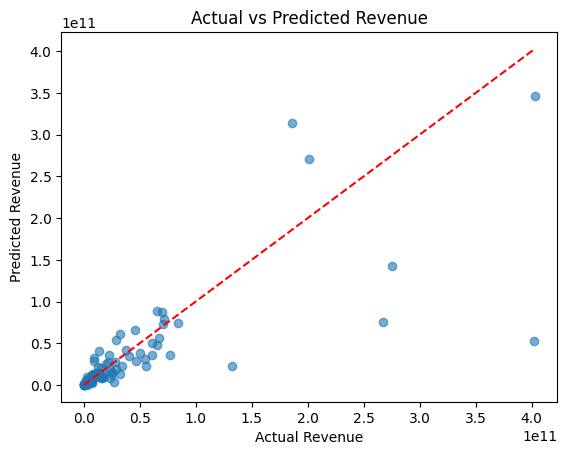

In [230]:
predicted = final_model.predict(X_test)

plt.scatter(y_test, predicted, alpha=0.6)

low = min(y_test.min(), predicted.min())
high = max(y_test.max(), predicted.max())
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue")
plt.show()

net_income                       7.209494e+09
market_cap                       6.300189e+09
employees                        5.454029e+09
legal_units_count                3.061605e+08
max_hierarchy_depth              1.043060e+08
company_type_PUBLIC              1.013226e+08
market_cap_source                6.332652e+07
enterprise_group_jurisdiction    5.022850e+07
employees_year                   4.031196e+07
revenue_source                   3.007903e+07
dtype: float64


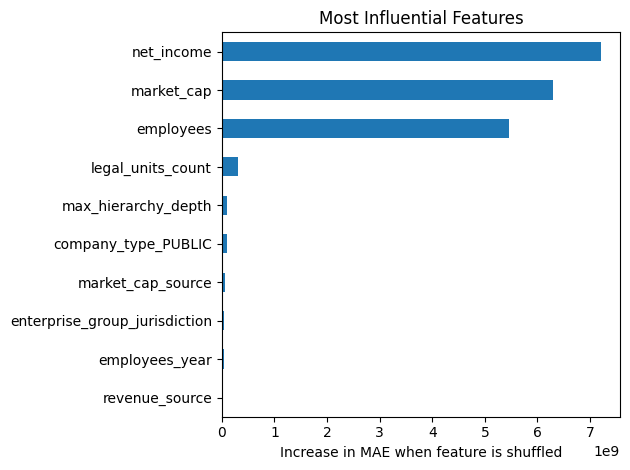

In [232]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

result = permutation_importance(
    final_model, X_test, y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=10,
    random_state=42
)

importance = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values()

print(importance.sort_values(ascending=False).head(10))

importance.tail(10).plot(kind="barh")
plt.xlabel("Increase in MAE when feature is shuffled")
plt.title("Most Influential Features")
plt.tight_layout()
plt.show()

In [233]:
import pickle


In [234]:
saved_data = {
    'model': final_model,
    'feature_columns': X_train.columns.tolist(),
    'numeric_features': numeric_features,
    'label_encoder': None
}

In [235]:
with open('model.pkl', 'wb') as file:
    pickle.dump(saved_data, file)


In [236]:
with open('model.pkl', 'rb') as file:
    loaded_data = pickle.load(file)


In [237]:
loaded_data['model'].predict(X_test.iloc[[0]])


array([9.55460021e+09])